# Onde está o faturamento de 2025?

**Pergunta:** como o faturamento de 2025 se divide por região, por mês e por canal de venda — para decidir onde concentrar o esforço comercial em 2026.

**Faturamento** = quantidade × preço unitário de cada venda.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

## Carregando e conferindo os dados
O arquivo foi lido com acentos e números corretos (5.000 linhas, 8 colunas).

In [2]:
df = pd.read_csv("dados/vendas.csv")
df.shape

(5000, 8)

In [3]:
df.head()

,data,produto,categoria,regiao,quantidade,preco_unitario,custo_unitario,canal_venda
0,2025-01-01,Mouse,Acessórios,Centro-Oeste,5,52.97,30.53,Online
1,2025-01-01,Monitor,Eletrônicos,Sul,7,1118.13,765.68,Loja física
2,2025-01-01,Tablet,Eletrônicos,Centro-Oeste,6,1611.59,959.28,Marketplace
3,2025-01-01,Monitor,Eletrônicos,Nordeste,4,953.18,559.37,Loja física
4,2025-01-01,Teclado,Acessórios,Sul,6,174.44,124.57,Online


In [4]:
df.dtypes.to_frame("tipo")

,tipo
data,str
produto,str
categoria,str
regiao,str
quantidade,int64
preco_unitario,float64
custo_unitario,float64
canal_venda,str


Os números saíram como números e os acentos estão certos. Agora, a checagem de qualidade: tem dado faltando ou repetido? Os valores fazem sentido? As categorias estão escritas de um jeito só?

In [5]:
pd.DataFrame({"faltando": df.isna().sum(), "duplicadas": df.duplicated().sum()})

,faltando,duplicadas
data,0,0
produto,0,0
categoria,0,0
regiao,154,0
quantidade,0,0
preco_unitario,0,0
custo_unitario,0,0
canal_venda,0,0


In [6]:
df[["quantidade", "preco_unitario", "custo_unitario"]].describe().T

,count,mean,std,min,25%,50%,75%,max
quantidade,5000.0,5.242400,2.842122,1.00,3.0000,5.000,8.0000,10.00
preco_unitario,5000.0,1011.605108,976.758235,50.10,306.1200,637.000,1400.7725,3599.30
custo_unitario,5000.0,643.894572,626.428442,28.84,192.2275,402.055,852.2525,2577.01


In [7]:
for c in ["regiao", "canal_venda", "categoria", "produto"]:
    print(c, sorted(df[c].dropna().unique()))
print(df["data"].min(), df["data"].max())

regiao ['Centro-Oeste', 'Nordeste', 'Norte', 'Sudeste', 'Sul']
canal_venda ['Loja física', 'Marketplace', 'Online']
categoria ['Acessórios', 'Eletrônicos', 'Móveis']
produto ['Cadeira', 'Estante', 'Gaveteiro', 'Headset', 'Mesa', 'Monitor', 'Mouse', 'Notebook', 'Smartphone', 'Tablet', 'Teclado', 'Webcam']
2025-01-01 2025-12-31


### O que a checagem dos dados mostrou
- 5.000 vendas, de 01/01/2025 a 31/12/2025, sem linhas repetidas.
- Nenhuma venda com preço abaixo do custo; quantidades de 1 a 10.
- **154 vendas sem região** (`2,9%` do faturamento). Não vamos descartá-las, para o total fechar: entram como "Sem região informada".
- Há mais vendas no fim do ano (243 em janeiro, 745 em dezembro) — será olhado na análise por mês.

Agora criamos o faturamento (quantidade × preço) e tratamos a região faltante.

In [8]:
df["faturamento"] = df["quantidade"] * df["preco_unitario"]
df["data"] = pd.to_datetime(df["data"])
df["mes"] = df["data"].dt.month
print("preço abaixo do custo:", (df["preco_unitario"] < df["custo_unitario"]).sum())
print("faturamento sem região:", round(df.loc[df["regiao"].isna(), "faturamento"].sum() / df["faturamento"].sum() * 100, 1), "%")
df.groupby("mes").size().to_frame("vendas").T

preço abaixo do custo: 0
faturamento sem região: 2.9 %


mes,1,2,3,4,5,6,7,8,9,10,11,12
vendas,243,249,362,335,393,358,383,435,411,432,654,745


In [9]:
df["regiao"] = df["regiao"].fillna("Sem região informada")
df["regiao"].value_counts().to_frame("vendas")

,vendas
regiao,
Sudeste,1933
Sul,875
Nordeste,857
Norte,591
Centro-Oeste,590
Sem região informada,154


In [10]:
total = df["faturamento"].sum()
def reais(v):
    return f"R$ {v:,.0f}".replace(",", ".")
reais(total)

'R$ 25.016.140'

O faturamento total de 2025 é de `R$ 25,0 milhões`.

### Quanto cada região fatura?
Faturamento, número de vendas, participação no total e valor médio por venda, por região.

In [11]:
reg = df.groupby("regiao")["faturamento"].agg(["sum", "count"]).sort_values("sum", ascending=False)
reg["% do total"] = (reg["sum"] / total * 100).round(1)
reg["ticket médio"] = (reg["sum"] / reg["count"]).round(0)
reg.rename(columns={"sum": "faturamento", "count": "vendas"})

,faturamento,vendas,% do total,ticket médio
regiao,,,,
Sudeste,9827937.32,1933,39.3,5084.0
Sul,4380944.08,875,17.5,5007.0
Nordeste,4140642.33,857,16.6,4832.0
Centro-Oeste,3086274.60,590,12.3,5231.0
Norte,2854711.86,591,11.4,4830.0
Sem região informada,725629.43,154,2.9,4712.0


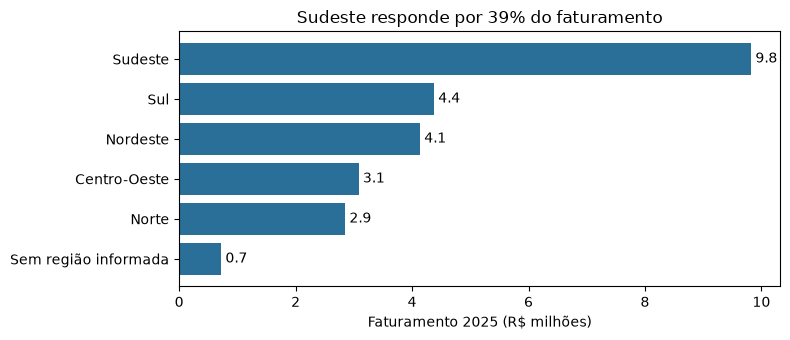

In [12]:
ordem = reg["sum"].sort_values()
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(ordem.index, ordem / 1e6, color="#2a6f97")
ax.set_xlabel("Faturamento 2025 (R$ milhões)")
ax.set_title("Sudeste responde por 39% do faturamento")
for i, v in enumerate(ordem / 1e6):
    ax.text(v, i, f" {v:.1f}", va="center")
plt.tight_layout()

**Resultado:** o Sudeste fatura `R$ 9,8 mi` (`39,3%`), mais que o dobro do Sul. O valor médio por venda é parecido entre regiões (`R$ 4,8 a 5,2 mil`), então a diferença vem da quantidade de vendas.

### Como o faturamento varia mês a mês?

In [13]:
mes = df.groupby("mes")["faturamento"].sum()
mes.to_frame("faturamento").assign(**{"% do total": (mes / total * 100).round(1)}).T.round(0)

mes,1,2,3,4,5,6,7,8,9,10,11,12
faturamento,1108187.0,1341894.0,1740646.0,1715095.0,1896749.0,1681848.0,1991034.0,2073661.0,2108097.0,2216607.0,3503635.0,3638687.0
% do total,4.0,5.0,7.0,7.0,8.0,7.0,8.0,8.0,8.0,9.0,14.0,14.0


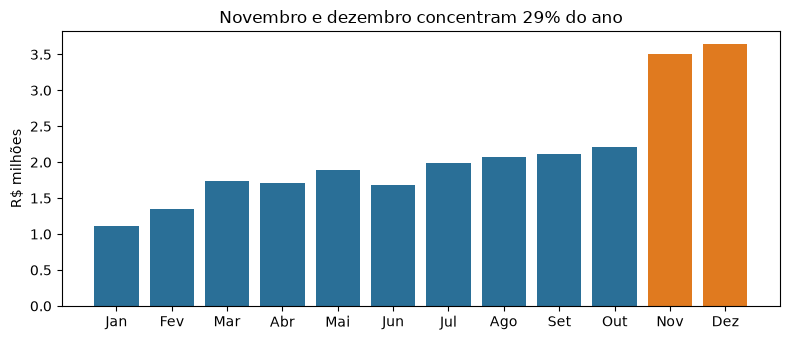

In [14]:
nomes = ["Jan", "Fev", "Mar", "Abr", "Mai", "Jun", "Jul", "Ago", "Set", "Out", "Nov", "Dez"]
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(nomes, mes / 1e6, color=["#2a6f97"] * 10 + ["#e07a1f"] * 2)
ax.set_ylabel("R$ milhões")
ax.set_title("Novembro e dezembro concentram 29% do ano")
plt.tight_layout()

**Resultado:** janeiro é o mês mais fraco (`R$ 1,1 mi`), há crescimento gradual até outubro (`R$ 2,2 mi`) e um salto em novembro (`R$ 3,5 mi`) e dezembro (`R$ 3,6 mi`) — `29%` do ano em dois meses. Com um único ano não dá para separar sazonalidade de crescimento.

### Quanto cada canal de venda fatura?

In [15]:
can = df.groupby("canal_venda")["faturamento"].agg(["sum", "count"]).sort_values("sum", ascending=False)
can["% do total"] = (can["sum"] / total * 100).round(1)
can["ticket médio"] = (can["sum"] / can["count"]).round(0)
can.rename(columns={"sum": "faturamento", "count": "vendas"})

,faturamento,vendas,% do total,ticket médio
canal_venda,,,,
Online,11155638.64,2213,44.6,5041.0
Loja física,7982486.44,1561,31.9,5114.0
Marketplace,5878014.54,1226,23.5,4794.0


**Resultado:** o Online é o maior canal (`44,6%`), seguido da Loja física (`31,9%`) e do Marketplace (`23,5%`). O valor médio por venda é parecido nos três.

### Cada região vende por canais diferentes?
Como o faturamento de cada região se divide entre os canais (linhas somam 100%).

In [16]:
cruz = df.pivot_table(index="regiao", columns="canal_venda", values="faturamento", aggfunc="sum")
(cruz.div(cruz.sum(axis=1), axis=0) * 100).round(1).assign(faturamento_mi=(cruz.sum(axis=1) / 1e6).round(1)).sort_values("faturamento_mi", ascending=False)

canal_venda,Loja física,Marketplace,Online,faturamento_mi
regiao,,,,
Sudeste,33.4,21.9,44.6,9.8
Sul,33.6,20.9,45.5,4.4
Nordeste,28.5,27.7,43.8,4.1
Centro-Oeste,31.7,23.7,44.5,3.1
Norte,30.0,26.6,43.4,2.9
Sem região informada,29.0,23.0,48.1,0.7


**Resultado:** a divisão por canal é parecida em todas as regiões (Online perto de `44%`). A diferença mais visível é o Nordeste, com mais Marketplace (`27,7%`) e menos Loja física (`28,5%`).

### Faturar mais também significa lucrar mais?
Margem = (faturamento menos custo) dividido pelo faturamento, por região e por canal.

In [17]:
df["lucro"] = df["faturamento"] - df["quantidade"] * df["custo_unitario"]
def margem(col):
    g = df.groupby(col)[["lucro", "faturamento"]].sum()
    return (g["lucro"] / g["faturamento"] * 100).round(1)
pd.DataFrame({"região": margem("regiao")}).join(pd.DataFrame({"canal": margem("canal_venda")}), how="outer")

,região,canal
regiao,,
Centro-Oeste,36.5,NaN
Loja física,NaN,36.4
Marketplace,NaN,36.2
Nordeste,36.4,NaN
Norte,36.4,NaN
Online,NaN,36.4
Sem região informada,36.3,NaN
Sudeste,36.3,NaN
Sul,36.3,NaN


**Resultado:** a margem é praticamente a mesma em tudo (`36%`). Faturar mais significa lucrar mais, em qualquer região ou canal.

### O salto de novembro e dezembro é de uma região ou canal específico?
Quanto do faturamento anual de cada região e canal cai em novembro e dezembro.

In [18]:
df["periodo"] = df["mes"].map(lambda m: "Nov-Dez" if m >= 11 else "Jan-Out")
def peso(col):
    t = df.pivot_table(index=col, columns="periodo", values="faturamento", aggfunc="sum")
    return (t["Nov-Dez"] / t.sum(axis=1) * 100).round(1)
pd.concat([peso("regiao"), peso("canal_venda")]).to_frame("% do ano em Nov-Dez")

,% do ano em Nov-Dez
Centro-Oeste,30.4
Nordeste,27.7
Norte,26.9
Sem região informada,34.8
Sudeste,30.2
Sul,24.4
Loja física,30.1
Marketplace,25.9
Online,28.8


**Resultado:** o salto de fim de ano aparece em todas as regiões e canais (entre `24%` e `35%` do faturamento de cada um cai em novembro e dezembro). Não é um fenômeno de uma região só; é do negócio inteiro.

## Conclusão: onde está o faturamento de 2025

Em 2025 a empresa faturou `R$ 25,0 milhões` em 5.000 vendas.

- **Região:** o Sudeste sozinho tem `39%` (`R$ 9,8 mi`). Sul (`17,5%`) e Nordeste (`16,6%`) vêm a seguir; Centro-Oeste (`12,3%`) e Norte (`11,4%`) fecham. O valor médio por venda é parecido em todas (`R$ 4,8 a 5,2 mil`): o Sudeste lidera porque vende **mais vezes**, não porque vende mais caro.
- **Mês:** o ano começa fraco (`R$ 1,1 mi` em janeiro), cresce até outubro (`R$ 2,2 mi`) e dispara em novembro e dezembro (`R$ 3,5 mi` e `R$ 3,6 mi`), que juntos somam `29%` do ano.
- **Canal:** Online `44,6%`, Loja física `31,9%`, Marketplace `23,5%`. A divisão entre canais é quase igual em todas as regiões. A exceção é o Nordeste, onde o Marketplace pesa um pouco mais (`28%`, contra `22%` no Sudeste).
- **Rentabilidade:** a margem é de cerca de `36%` em toda região e todo canal. Portanto, onde o faturamento é maior, o lucro também é maior; nenhum canal ou região "paga menos".

**O que isso sugere para 2026**
1. Proteger o que já sustenta o resultado: **Sudeste e canal Online**, que juntos são a maior fatia e têm a mesma margem dos demais.
2. Planejar estoque, equipe e campanhas para **novembro e dezembro**, quando se concentra quase um terço do faturamento.
3. Para crescer fora do Sudeste, a decisão é de aposta, não de correção: as outras regiões vendem o mesmo tipo de ticket, só em menor quantidade.

**Limites da análise**
- Temos só 2025. Não dá para dizer se o pico de fim de ano é sazonal (Black Friday, Natal) ou se as vendas estão crescendo; a diferença precisa de 2024 para ser confirmada.
- A fatia de cada região mostra o que foi vendido, não o **potencial** dela. Para saber se o Norte ou o Centro-Oeste têm espaço para crescer, faltam dados de mercado (população, concorrência).
- `2,9%` do faturamento (`R$ 0,7 mi`, 154 vendas) não tem região registrada. Ficou em "Sem região informada" e não muda a ordem do ranking.